In [1]:
!pip install tensorflow opencv-python matplotlib

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [9]:
import os
import zipfile


# Move it to the right place
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the dataset
!kaggle datasets download -d jay7080dev/rice-plant-diseases-dataset

# Unzip the dataset
with zipfile.ZipFile("rice-plant-diseases-dataset.zip", 'r') as zip_ref:
    zip_ref.extractall("rice_dataset")


Dataset URL: https://www.kaggle.com/datasets/jay7080dev/rice-plant-diseases-dataset
License(s): apache-2.0
rice-plant-diseases-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [15]:
dataset_path = '/content/rice_dataset/rice leaf diseases dataset'
img_size = 128
batch_size = 32


In [16]:
train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',  # This is correct for multi-class classification
    subset='training',
    shuffle=True
)

val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',  # This must match the model output
    subset='validation',
    shuffle=False
)


Found 3748 images belonging to 3 classes.
Found 936 images belonging to 3 classes.


In [17]:
from tensorflow.keras import Input

model = Sequential([
    Input(shape=(img_size, img_size, 3)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')  # 3 classes
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stop = EarlyStopping(patience=5, restore_best_weights=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[early_stop]
)


Epoch 1/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.5657 - loss: 0.8845 - val_accuracy: 0.7981 - val_loss: 0.5929
Epoch 2/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.7771 - loss: 0.5836 - val_accuracy: 0.8472 - val_loss: 0.4092
Epoch 3/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.8302 - loss: 0.4286 - val_accuracy: 0.8675 - val_loss: 0.3484
Epoch 4/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.8863 - loss: 0.3113 - val_accuracy: 0.8953 - val_loss: 0.2827
Epoch 5/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.8996 - loss: 0.2582 - val_accuracy: 0.9060 - val_loss: 0.2363
Epoch 6/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.9207 - loss: 0.2225 - val_accuracy: 0.9423 - val_loss: 0.1429
Epoch 7/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9508 - loss: 0.1355 - val_accuracy: 0.9551 - val_loss: 0.1181
Epoch 8/25
118/118 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9374 - loss: 0.1798 - val_accu

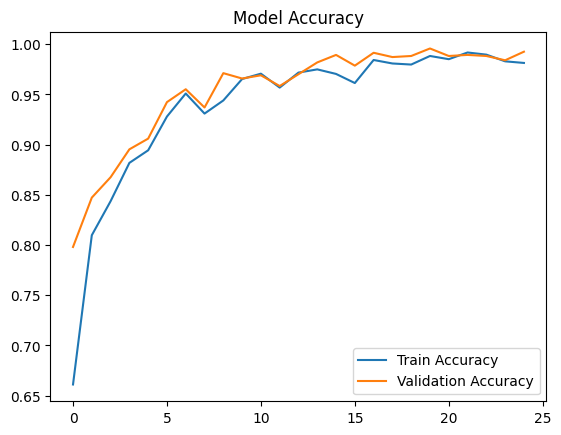

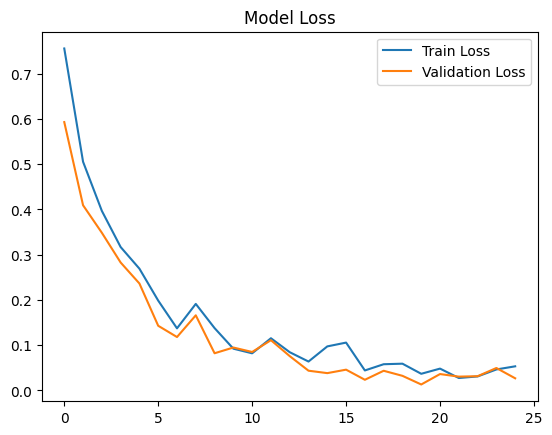

In [19]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')
plt.show()


30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 571ms/step
Classification Report:
                 precision    recall  f1-score   support

Bacterialblight       1.00      0.98      0.99       320
      Brownspot       1.00      1.00      1.00       324
       Leafsmut       0.98      1.00      0.99       292

       accuracy                           0.99       936
      macro avg       0.99      0.99      0.99       936
   weighted avg       0.99      0.99      0.99       936



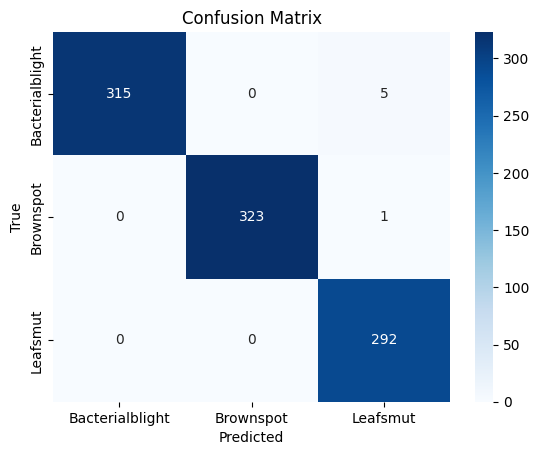

In [20]:
val_data.reset()
preds = model.predict(val_data)
y_pred = np.argmax(preds, axis=1)
y_true = val_data.classes

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=list(val_data.class_indices.keys())))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=val_data.class_indices.keys(),
            yticklabels=val_data.class_indices.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [21]:
model.save('rice_disease_cnn_model.h5')

Saving BACTERAILBLIGHT3_004.jpg to BACTERAILBLIGHT3_004.jpg


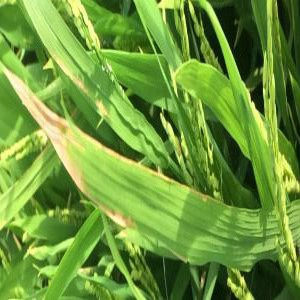

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
Predicted Class: Bacterialblight


In [26]:
from tensorflow.keras.models import load_model
import cv2
import numpy as np
from google.colab import files
from IPython.display import display, Image

# Load model and define class labels
model = load_model('/content/rice_disease_cnn_model.h5')
class_indices = {0: 'Bacterialblight', 1: 'Brownspot', 2: 'Leafsmut'}

# Upload image
uploaded = files.upload()
for filename in uploaded.keys():
    img_path = filename
    display(Image(filename))

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (128, 128))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)

    prediction = model.predict(img)
    class_idx = np.argmax(prediction)
    print(f"Predicted Class: {class_indices[class_idx]}")
